<a href="https://colab.research.google.com/github/fiaoqq/deteccao-fraude-cartao/blob/main/aula.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
!pip install -q imbalanced-learn shap xgboost

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, auc, precision_recall_curve)
from xgboost import XGBClassifier
import shap

sns.set_style("whitegrid")

In [18]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

print("Formato:", df.shape)
df.head()

Formato: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [19]:
print("Contagem por classe:")
print(df['Class'].value_counts())

print("\nProporção:")
print(df['Class'].value_counts(normalize=True) * 100)

Contagem por classe:
Class
0    284315
1       492
Name: count, dtype: int64

Proporção:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [20]:
# Log do valor (Amount tem cauda longa)
df['log_amount'] = np.log1p(df['Amount'])

# Padroniza Time e Amount (as V já vêm do PCA padronizadas)
scaler = StandardScaler()
df[['Time_scaled', 'Amount_scaled']] = scaler.fit_transform(df[['Time', 'Amount']])

# Remove as colunas originais e a 'Class' das features
X = df.drop(columns=['Class', 'Time', 'Amount'])
y = df['Class']

print(X.columns.tolist())

['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'log_amount', 'Time_scaled', 'Amount_scaled']


In [21]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print("Treino:", y_tr.value_counts(normalize=True).values)
print("Teste :", y_te.value_counts(normalize=True).values)

Treino: [0.99827451 0.00172549]
Teste : [0.99826785 0.00173215]


In [22]:
logreg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
logreg.fit(X_tr, y_tr)

y_pred_lr = logreg.predict(X_te)

print(classification_report(y_te, y_pred_lr, digits=4))

              precision    recall  f1-score   support

           0     0.9998    0.9782    0.9889     85295
           1     0.0653    0.8784    0.1216       148

    accuracy                         0.9780     85443
   macro avg     0.5326    0.9283    0.5552     85443
weighted avg     0.9982    0.9780    0.9874     85443



In [23]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced_subsample',
    random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)

y_pred_rf = rf.predict(X_te)
print(classification_report(y_te, y_pred_rf, digits=4))

              precision    recall  f1-score   support

           0     0.9995    1.0000    0.9997     85295
           1     0.9722    0.7095    0.8203       148

    accuracy                         0.9995     85443
   macro avg     0.9859    0.8547    0.9100     85443
weighted avg     0.9994    0.9995    0.9994     85443



In [24]:
peso = (y_tr == 0).sum() / (y_tr == 1).sum()

xgb = XGBClassifier(
    n_estimators=200, scale_pos_weight=peso,
    eval_metric='logloss', random_state=42, n_jobs=-1)
xgb.fit(X_tr, y_tr)

y_pred_xgb = xgb.predict(X_te)
print(classification_report(y_te, y_pred_xgb, digits=4))

              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9997     85295
           1     0.9062    0.7838    0.8406       148

    accuracy                         0.9995     85443
   macro avg     0.9529    0.8918    0.9202     85443
weighted avg     0.9995    0.9995    0.9995     85443



In [25]:
probs = rf.predict_proba(X_te)[:, 1]
prec, rec, th = precision_recall_curve(y_te, probs)

f1 = 2 * prec * rec / (prec + rec + 1e-9)
melhor_th = th[np.argmax(f1[:-1])]
print("Melhor limiar:", round(melhor_th, 3))

y_pred_ajustado = (probs >= melhor_th).astype(int)
print(classification_report(y_te, y_pred_ajustado, digits=4))

Melhor limiar: 0.29
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     85295
           1     0.9350    0.7770    0.8487       148

    accuracy                         0.9995     85443
   macro avg     0.9673    0.8885    0.9242     85443
weighted avg     0.9995    0.9995    0.9995     85443



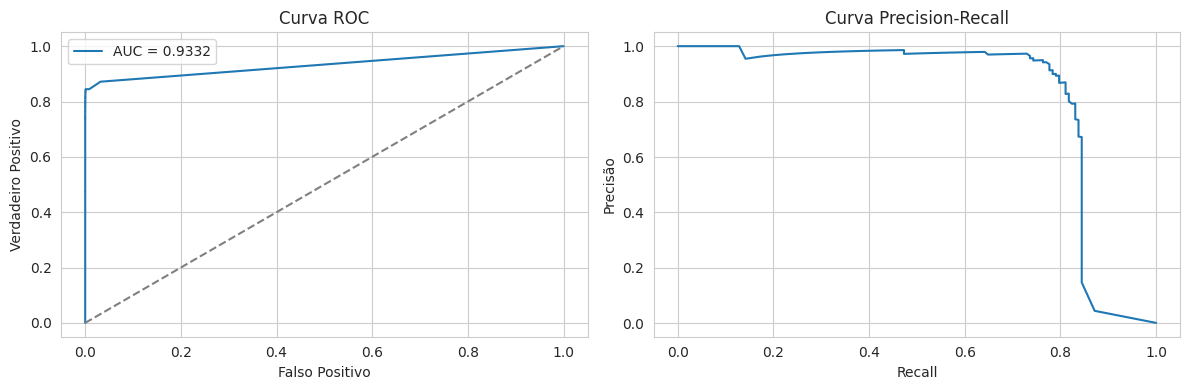

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))

# ROC
fpr, tpr, _ = roc_curve(y_te, probs)
ax[0].plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.4f}")
ax[0].plot([0,1],[0,1],'--', color='gray')
ax[0].set_title("Curva ROC")
ax[0].set_xlabel("Falso Positivo"); ax[0].set_ylabel("Verdadeiro Positivo")
ax[0].legend()

# Precision-Recall
ax[1].plot(rec, prec)
ax[1].set_title("Curva Precision-Recall")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisão")

plt.tight_layout(); plt.show()

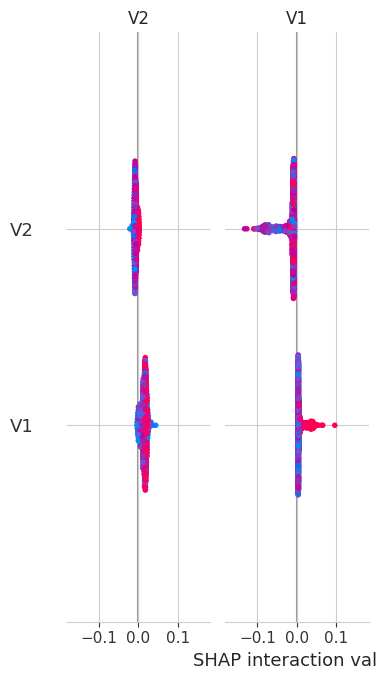

In [27]:
# Amostra do teste para acelerar o SHAP
X_amostra = X_te.sample(n=1000, random_state=42)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_amostra)

sv = shap_values[1] if isinstance(shap_values, list) else shap_values
shap.summary_plot(sv, X_amostra)